---

# CHAPTER 2: PREDICTIONS AND MODEL OBJECTS

---

<br><br>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('Resources/taiwan_real_estate2.csv')
df.head()

,dist_to_mrt_m,n_convenience,house_age_years,price_twd_msq
0,84.87882,10,30 to 45,11.467474
1,306.59470,9,15 to 30,12.768533
2,561.98450,5,0 to 15,14.311649
3,561.98450,5,0 to 15,16.580938
4,390.56840,5,0 to 15,13.040847


<br><br>

---

## 1. Making Predictions

<br>



<span style='color:orange'>

**Data on explanatory values to predict (*common question to ask*):**

>  - If I set the `explanatory variables` to these values, what value would the `response variable` have?

In [3]:
# Create the explanatory_data that goes from 0 to 10
explanatory_data = pd.DataFrame({'n_convenience':np.arange(11)})
explanatory_data

,n_convenience
0,0
1,1
2,2
3,3
4,4
5,5
6,6
7,7
8,8
9,9


In [6]:
from statsmodels.formula.api import ols

# Lets train and fit the model...
mdl_price_vs_conv = ols('price_twd_msq ~ n_convenience', data=df).fit()

# Use mdl_price_vs_conv to predict with explanatory_data, call it price_twd
price_twd = mdl_price_vs_conv.predict(explanatory_data)
price_twd

0      8.224237
1      9.022317
2      9.820397
3     10.618477
4     11.416556
5     12.214636
6     13.012716
7     13.810795
8     14.608875
9     15.406955
10    16.205035
dtype: float64

In [7]:
# Create prediction_data
prediction_data = explanatory_data.assign(price_twd = price_twd)
prediction_data

,n_convenience,price_twd
0,0,8.224237
1,1,9.022317
2,2,9.820397
3,3,10.618477
4,4,11.416556
5,5,12.214636
6,6,13.012716
7,7,13.810795
8,8,14.608875
9,9,15.406955


<br>

---

Now it's time to plot our new `predicted_data`...

<span style='color:red'>

>  - **To plot multiple layers**, we set a matplotlib `figure object` called `fig` before calling `regplot` and `scatterplot`. As a result, the `plt.show()` call will then plot both graphs on the same figure.
>
>  - **I've marked the prediction points** in `red squares` **to distinguish them from the actual data points**. `Notice that the predictions lie exactly on the trend line`.

---

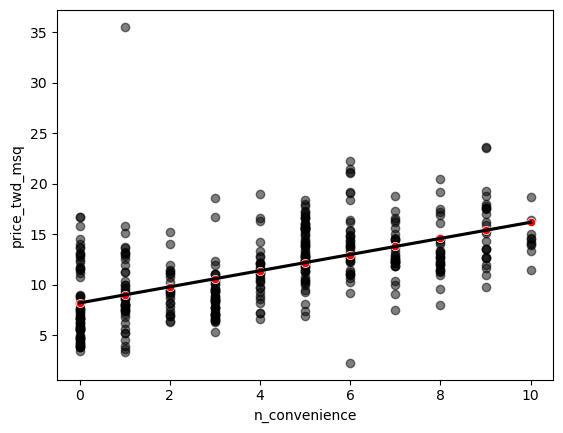

In [15]:
fig = plt.figure()

sns.regplot(data=df, x='n_convenience', 
            y='price_twd_msq', ci=None, 
            color='k', scatter_kws={'alpha':0.5})

sns.scatterplot(data=prediction_data, x='n_convenience', 
                y='price_twd', color='r')
plt.show()

<br><br>

Create some impossible explanatory data. Define a DataFrame impossible with one column, n_convenience, set to -1 in the first row, and 2.5 in the second row.

<span style='color:orange'>

---

>**Extrapolating means making predictions outside the range of observed data.**
>
>  -  Extrapolation is sometimes appropriate, but can lead to misleading or ridiculous results.
>
>  -  You need to understand the context of your data in order to determine whether it is sensible to extrapolate.

---

In [17]:
impossible = pd.DataFrame({'n_convenience':[-1, 2.5]})
impossible

,n_convenience
0,-1.0
1,2.5


In [18]:
# Try making predictions on your two impossible cases. What happens?
extrapolation = mdl_price_vs_conv.predict(impossible)
extrapolation

0     7.426158
1    10.219437
dtype: float64

<span style='color:orange'>
    
>---
>
>  - Linear models don't know what is possible or not in real life.
>
>  - That means that they can give you predictions that don't make any sense when applied to your data.
>
>  - You need to understand what your data means in order to determine whether a prediction is `nonsense` or `not`.
>
>---


<br><br>

---

## 2. Working with Model Objects

<br>


In [19]:
# Print the model parameters of mdl_price_vs_conv
mdl_price_vs_conv.params

Intercept        8.224237
n_convenience    0.798080
dtype: float64

In [20]:
# Print the fitted values of mdl_price_vs_conv
mdl_price_vs_conv.fittedvalues

0      16.205035
1      15.406955
2      12.214636
3      12.214636
4      12.214636
         ...    
409     8.224237
410    15.406955
411    13.810795
412    12.214636
413    15.406955
Length: 414, dtype: float64

In [21]:
# Print the residuals of mdl_price_vs_conv
mdl_price_vs_conv.resid

0     -4.737561
1     -2.638422
2      2.097013
3      4.366302
4      0.826211
         ...   
409   -3.564631
410   -0.278362
411   -1.526378
412    3.670387
413    3.927387
Length: 414, dtype: float64

In [22]:
# Print a summary of mdl_price_vs_conv
mdl_price_vs_conv.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          price_twd_msq   R-squared:                       0.326
Model:                            OLS   Adj. R-squared:                  0.324
Method:                 Least Squares   F-statistic:                     199.3
Date:                Tue, 29 Sep 2026   Prob (F-statistic):           3.41e-37
Time:                        12:10:16   Log-Likelihood:                -1091.1
No. Observations:                 414   AIC:                             2186.
Df Residuals:                     412   BIC:                             2194.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         8.2242      0.285     28.857      0.000       7.664       8.784
n_convenience     0.7981      0.057     14.118      0.000       0.687       0.909
==============================================================================
Omnibus:                      171.927   Durbin-Watson:                   1.993
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1417.242
Skew:                           1.553   Prob(JB):                    1.78e-308
Kurtosis:                      11.516   Cond. No.                         8.87
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [23]:
# Get the coefficients of mdl_price_vs_conv
coeffs = mdl_price_vs_conv.params
coeffs

Intercept        8.224237
n_convenience    0.798080
dtype: float64

In [27]:
# Get the intercept
intercept = coeffs.iloc[0]
intercept

np.float64(8.224237452790335)

In [28]:
# Get the slope
slope = coeffs.iloc[1]
slope

np.float64(0.798079716612508)

In [ ]:
# Manually calculate the predictions

In [29]:
price_twd_calc = intercept + slope*explanatory_data
price_twd_calc

,n_convenience
0,8.224237
1,9.022317
2,9.820397
3,10.618477
4,11.416556
5,12.214636
6,13.012716
7,13.810795
8,14.608875
9,15.406955


In [32]:
# Compare to the results from .predict()
price_twd_calc = price_twd_calc.assign(predictions_auto = mdl_price_vs_conv.predict(explanatory_data))
price_twd_calc

,n_convenience,predictions_auto
0,8.224237,8.224237
1,9.022317,9.022317
2,9.820397,9.820397
3,10.618477,10.618477
4,11.416556,11.416556
5,12.214636,12.214636
6,13.012716,13.012716
7,13.810795,13.810795
8,14.608875,14.608875
9,15.406955,15.406955


<br><br>

---

## 3. Regression to the Mean

<br>
